In [16]:
!pip -q install datasets

In [17]:
import os, re, random, collections, json, time
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report

# ---------------- CONFIG----------------
SEED          = 42
PER_CELL      = 400      # target rows per (family, domain) pair, split evenly across the family's models
DOMAINS       = ["abstracts", "books", "news", "poetry"]   # domains to collect (the first four in the file)
MAX_STREAM    = 3_000_000  # safety cap on how many RAID rows we scan
CACHE         = "raid_subset_v2.csv"
VOCAB_SIZE    = 20_000
MAX_LEN_IN    = 64       # tokens kept from the prompt
MAX_LEN_OUT   = 256      # tokens kept from the generation
EMB_DIM       = 128
BATCH         = 64
EPOCHS        = 12
LR            = 1e-3
HELD_OUT      = ["poetry", "abstracts"]   # domains tested one at a time in RQ3
OUT_DIR       = "results"

# RAID model name -> LLM family
FAMILY = {
    "chatgpt": "OpenAI-GPT", "gpt4": "OpenAI-GPT", "gpt3": "OpenAI-GPT",
    "llama-chat": "Meta-Llama",
    "mistral": "Mistral", "mistral-chat": "Mistral"
}

# Rows to keep per (model, domain): the family target divided by how many models the family has.
# llama-chat -> 400, mistral / mistral-chat -> 200 each, chatgpt / gpt4 / gpt3 -> 133 each (399 per family).
QUOTA = {m: PER_CELL // sum(f == fam for f in FAMILY.values()) for m, fam in FAMILY.items()}

def set_seed(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

set_seed()
os.makedirs(OUT_DIR, exist_ok=True)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", DEVICE)

device: cuda


In [18]:
if os.path.exists(CACHE):
    df = pd.read_csv(CACHE)
    print("loaded cached subset:", df.shape)
else:
    from datasets import load_dataset
    stream = load_dataset("liamdugan/raid", split="train", streaming=True)
    counts, rows, t0 = collections.Counter(), [], time.time()
    n_pairs, n_full = len(FAMILY) * len(DOMAINS), 0      # every (model, domain) pair has its own quota
    for i, r in enumerate(stream):
        if i >= MAX_STREAM: break
        if i % 100_000 == 0:
            print(f"scanned {i:,} rows, kept {len(rows):,}, {n_full}/{n_pairs} model-domain pairs full ({time.time()-t0:.0f}s)")
        m, dom = r["model"], r["domain"]
        if m not in FAMILY or dom not in DOMAINS or r["attack"] != "none" or not r["generation"]: continue
        key = (m, dom)
        if counts[key] >= QUOTA[m]: continue             # this model already has its share for this domain
        counts[key] += 1
        rows.append({"source_id": r["source_id"], "model": m, "family": FAMILY[m],
                     "domain": dom, "decoding": r["decoding"],
                     "input": r["prompt"] or "", "output": r["generation"]})
        if counts[key] == QUOTA[m]:
            n_full += 1
            if n_full == n_pairs: break                  # every pair is full -> stop streaming
    df = pd.DataFrame(rows)
    df.to_csv(CACHE, index=False)
    print(f"built subset: {df.shape}, scanned {i:,} rows, {n_full}/{n_pairs} model-domain pairs full")

df = df[df.model.isin(list(FAMILY)) & df.domain.isin(DOMAINS)].reset_index(drop=True)
df["input"] = df["input"].fillna("").astype(str)
df["output"] = df["output"].fillna("").astype(str)
CLASSES = sorted(df["family"].unique())
LABEL = {c: i for i, c in enumerate(CLASSES)}
df["y"] = df["family"].map(LABEL)

# Tables for the report: rows per family per domain, and rows per model per domain
display(pd.crosstab(df["family"], df["domain"], margins=True))
display(pd.crosstab([df["family"], df["model"]], df["domain"], margins=True))

loaded cached subset: (4796, 7)


domain,abstracts,books,news,poetry,All
family,,,,,
Meta-Llama,400,400,400,400,1600
Mistral,400,400,400,400,1600
OpenAI-GPT,399,399,399,399,1596
All,1199,1199,1199,1199,4796


domain                   abstracts  books  news  poetry   All
family     model                                             
Meta-Llama llama-chat          400    400   400     400  1600
Mistral    mistral             200    200   200     200   800
           mistral-chat        200    200   200     200   800
OpenAI-GPT chatgpt             133    133   133     133   532
           gpt3                133    133   133     133   532
           gpt4                133    133   133     133   532
All                           1199   1199  1199    1199  4796

In [19]:
def group_split(d, seed=SEED):
    g1 = GroupShuffleSplit(n_splits=1, test_size=0.30, random_state=seed)
    tr, rest = next(g1.split(d, groups=d["source_id"]))
    rest_df = d.iloc[rest]
    g2 = GroupShuffleSplit(n_splits=1, test_size=0.50, random_state=seed)
    va, te = next(g2.split(rest_df, groups=rest_df["source_id"]))
    return d.iloc[tr].reset_index(drop=True), rest_df.iloc[va].reset_index(drop=True), rest_df.iloc[te].reset_index(drop=True)

train_df, val_df, test_df = group_split(df)
print({k: len(v) for k, v in [("train", train_df), ("val", val_df), ("test", test_df)]})
print("chance accuracy:", round(1 / len(CLASSES), 3))

{'train': 3319, 'val': 786, 'test': 691}
chance accuracy: 0.333


In [20]:
TOKEN_RE = re.compile(r"\n|\w+|[^\w\s]")
PAD, UNK, SEP = 0, 1, 2

def tokenize(text):
    return TOKEN_RE.findall(text)

def build_vocab(texts, size=VOCAB_SIZE):
    c = collections.Counter(t for x in texts for t in tokenize(x))
    itos = ["<pad>", "<unk>", "<sep>"] + [w for w, _ in c.most_common(size - 3)]
    return {w: i for i, w in enumerate(itos)}

def encode(text, vocab, max_len):
    return [vocab.get(t, UNK) for t in tokenize(text)[:max_len]]

def make_ids(row, vocab, mode):
    """mode: 'input' = prompt only, 'output' = generation only, 'both' = prompt <sep> generation."""
    if mode == "input":  ids = encode(row["input"], vocab, MAX_LEN_IN)
    elif mode == "output": ids = encode(row["output"], vocab, MAX_LEN_OUT)
    else: ids = encode(row["input"], vocab, MAX_LEN_IN) + [SEP] + encode(row["output"], vocab, MAX_LEN_OUT)
    return ids or [UNK]          # never return an empty sequence

class TextDS(Dataset):
    def __init__(self, d, vocab, mode):
        self.x = [make_ids(r, vocab, mode) for r in d.to_dict("records")]
        self.y = d["y"].tolist()
    def __len__(self): return len(self.y)
    def __getitem__(self, i): return self.x[i], self.y[i]

def collate(batch):
    """Pad every sequence in the batch to the longest one; also return true lengths for the LSTM."""
    xs, ys = zip(*batch)
    L = max(max(len(x) for x in xs), 5)       # at least 5 so the CNN's widest kernel fits
    out = torch.zeros(len(xs), L, dtype=torch.long)
    for i, x in enumerate(xs): out[i, :len(x)] = torch.tensor(x)
    return out, torch.tensor([len(x) for x in xs]), torch.tensor(ys)

def loader(d, vocab, mode, shuffle=False):
    return DataLoader(TextDS(d, vocab, mode), batch_size=BATCH, shuffle=shuffle, collate_fn=collate)

In [21]:
class TextCNN(nn.Module):
    def __init__(self, vocab_size, n_classes, emb=EMB_DIM, n_filters=100, kernels=(3, 4, 5), drop=0.5):
        super().__init__()
        self.emb = nn.Embedding(vocab_size, emb, padding_idx=PAD)
        self.convs = nn.ModuleList([nn.Conv1d(emb, n_filters, k) for k in kernels])
        self.drop = nn.Dropout(drop)
        self.fc = nn.Linear(n_filters * len(kernels), n_classes)
    def forward(self, x, lengths=None):
        e = self.emb(x).transpose(1, 2)                       # (batch, emb, seq)
        pooled = [torch.relu(c(e)).max(dim=2).values for c in self.convs]
        return self.fc(self.drop(torch.cat(pooled, dim=1)))

class BiLSTM(nn.Module):
    def __init__(self, vocab_size, n_classes, emb=EMB_DIM, hidden=128, drop=0.5):
        super().__init__()
        self.emb = nn.Embedding(vocab_size, emb, padding_idx=PAD)
        self.lstm = nn.LSTM(emb, hidden, batch_first=True, bidirectional=True)
        self.drop = nn.Dropout(drop)
        self.fc = nn.Linear(hidden * 2, n_classes)
    def forward(self, x, lengths):
        packed = nn.utils.rnn.pack_padded_sequence(self.emb(x), lengths.cpu(), batch_first=True, enforce_sorted=False)
        _, (h, _) = self.lstm(packed)                         # h: (2, batch, hidden)
        return self.fc(self.drop(torch.cat([h[0], h[1]], dim=1)))

MODELS = {"CNN": TextCNN, "LSTM": BiLSTM}

In [22]:
@torch.no_grad()
def predict(model, dl):
    model.eval(); preds, gold = [], []
    for x, l, y in dl:
        preds += model(x.to(DEVICE), l).argmax(1).cpu().tolist(); gold += y.tolist()
    return np.array(gold), np.array(preds)

def fit(arch, tr, va, mode, epochs=EPOCHS, verbose=True):
    set_seed()
    vocab = build_vocab(tr["input"] if mode == "input" else tr["output"] if mode == "output"
                        else pd.concat([tr["input"], tr["output"]]))
    model = MODELS[arch](len(vocab), len(CLASSES)).to(DEVICE)
    opt, lossf = torch.optim.Adam(model.parameters(), lr=LR), nn.CrossEntropyLoss()
    dl_tr, dl_va = loader(tr, vocab, mode, shuffle=True), loader(va, vocab, mode)
    best, best_state, hist = -1, None, []
    for ep in range(1, epochs + 1):
        model.train(); tot = 0
        for x, l, y in dl_tr:
            opt.zero_grad()
            loss = lossf(model(x.to(DEVICE), l), y.to(DEVICE))
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 5.0)   # keeps LSTM gradients stable
            opt.step(); tot += loss.item() * len(y)
        g, p = predict(model, dl_va); acc = accuracy_score(g, p)
        hist.append({"epoch": ep, "train_loss": tot / len(tr), "val_acc": acc})
        if verbose: print(f"  {arch}/{mode} epoch {ep}: loss {tot/len(tr):.3f}  val acc {acc:.3f}")
        if acc > best:
            best, best_state = acc, {k: v.detach().clone() for k, v in model.state_dict().items()}
    model.load_state_dict(best_state)
    return model, vocab, hist

def evaluate(model, vocab, d, mode):
    g, p = predict(model, loader(d, vocab, mode))
    return {"acc": accuracy_score(g, p), "macro_f1": f1_score(g, p, average="macro")}, g, p

def plot_cm(g, p, title, fname):
    cm = confusion_matrix(g, p, labels=range(len(CLASSES)), normalize="true")
    fig, ax = plt.subplots(figsize=(5.5, 4.5)); im = ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(len(CLASSES)), CLASSES, rotation=40, ha="right"); ax.set_yticks(range(len(CLASSES)), CLASSES)
    for i in range(len(CLASSES)):
        for j in range(len(CLASSES)):
            ax.text(j, i, f"{cm[i,j]:.2f}", ha="center", va="center", color="white" if cm[i, j] > 0.5 else "black", fontsize=8)
    ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title(title); fig.colorbar(im)
    fig.tight_layout(); fig.savefig(f"{OUT_DIR}/{fname}", dpi=150); plt.show()

In [23]:
# One example prompt per model, to see how prompt wording differs between chat and non-chat models
for (fam, model), g in df.groupby(["family", "model"]):
    print(f"[{fam} / {model}] {g['input'].iloc[0][:200]!r}\n")

[Meta-Llama / llama-chat] 'Write the abstract for the academic paper titled "FUTURE-AI: Guiding Principles and Consensus Recommendations for Trustworthy Artificial Intelligence in Future Medical Imaging".'

[Mistral / mistral] 'The following is the full text of the abstract for a research paper titled "FUTURE-AI: Guiding Principles and Consensus Recommendations for Trustworthy Artificial Intelligence in Future Medical Imagin'

[Mistral / mistral-chat] 'Write the abstract for the academic paper titled "FUTURE-AI: Guiding Principles and Consensus Recommendations for Trustworthy Artificial Intelligence in Future Medical Imaging".'

[OpenAI-GPT / chatgpt] 'Write the abstract for the academic paper titled "FUTURE-AI: Guiding Principles and Consensus Recommendations for Trustworthy Artificial Intelligence in Future Medical Imaging".'

[OpenAI-GPT / gpt3] 'The following is the full text of the abstract for a research paper titled "FUTURE-AI: Guiding Principles and Consensus Recommendations fo

  CNN/input epoch 1: loss 1.136  val acc 0.422
  CNN/input epoch 2: loss 1.018  val acc 0.471
  CNN/input epoch 3: loss 0.945  val acc 0.471
  CNN/input epoch 4: loss 0.901  val acc 0.440
  CNN/input epoch 5: loss 0.887  val acc 0.448
  CNN/input epoch 6: loss 0.860  val acc 0.438
  CNN/input epoch 7: loss 0.850  val acc 0.458
  CNN/input epoch 8: loss 0.841  val acc 0.463
  CNN/input epoch 9: loss 0.832  val acc 0.466
  CNN/input epoch 10: loss 0.818  val acc 0.458
  CNN/input epoch 11: loss 0.835  val acc 0.466
  CNN/input epoch 12: loss 0.813  val acc 0.468


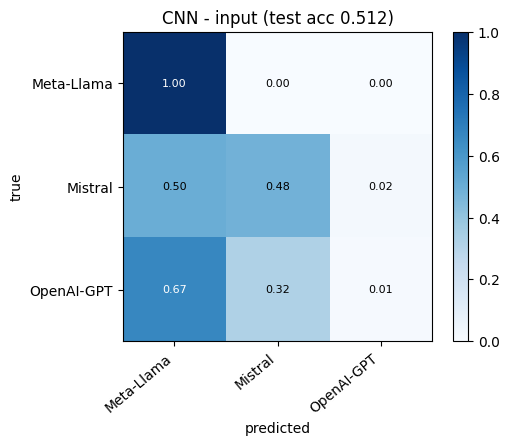

  CNN/output epoch 1: loss 1.226  val acc 0.483
  CNN/output epoch 2: loss 0.958  val acc 0.588
  CNN/output epoch 3: loss 0.827  val acc 0.682
  CNN/output epoch 4: loss 0.753  val acc 0.667
  CNN/output epoch 5: loss 0.662  val acc 0.653
  CNN/output epoch 6: loss 0.582  val acc 0.707
  CNN/output epoch 7: loss 0.537  val acc 0.714
  CNN/output epoch 8: loss 0.494  val acc 0.718
  CNN/output epoch 9: loss 0.441  val acc 0.711
  CNN/output epoch 10: loss 0.415  val acc 0.724
  CNN/output epoch 11: loss 0.376  val acc 0.739
  CNN/output epoch 12: loss 0.316  val acc 0.718


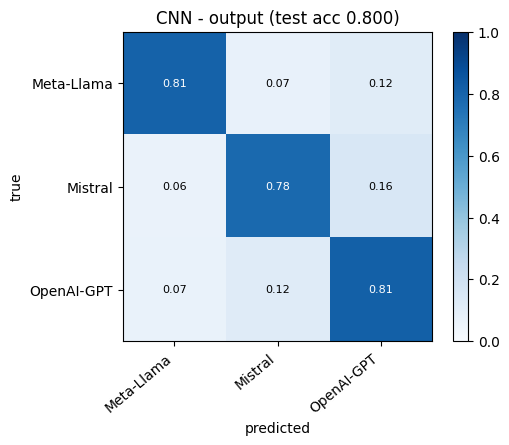

              precision    recall  f1-score   support

  Meta-Llama      0.866     0.808     0.836       240
     Mistral      0.804     0.780     0.792       232
  OpenAI-GPT      0.736     0.813     0.772       219

    accuracy                          0.800       691
   macro avg      0.802     0.800     0.800       691
weighted avg      0.804     0.800     0.801       691

  CNN/both epoch 1: loss 1.114  val acc 0.599
  CNN/both epoch 2: loss 0.780  val acc 0.752
  CNN/both epoch 3: loss 0.642  val acc 0.785
  CNN/both epoch 4: loss 0.577  val acc 0.799
  CNN/both epoch 5: loss 0.471  val acc 0.784
  CNN/both epoch 6: loss 0.411  val acc 0.821
  CNN/both epoch 7: loss 0.386  val acc 0.818
  CNN/both epoch 8: loss 0.337  val acc 0.812
  CNN/both epoch 9: loss 0.302  val acc 0.804
  CNN/both epoch 10: loss 0.284  val acc 0.819
  CNN/both epoch 11: loss 0.261  val acc 0.826
  CNN/both epoch 12: loss 0.210  val acc 0.816


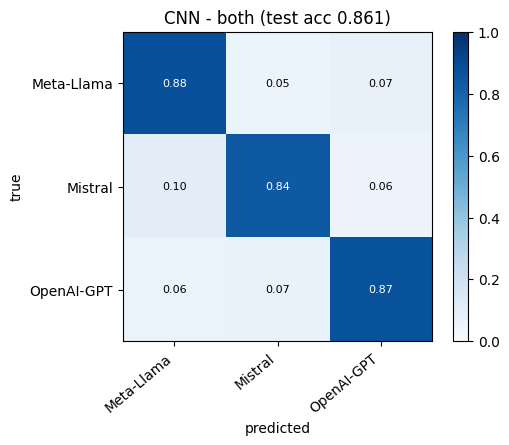

  LSTM/input epoch 1: loss 0.971  val acc 0.473
  LSTM/input epoch 2: loss 0.963  val acc 0.473
  LSTM/input epoch 3: loss 0.957  val acc 0.471
  LSTM/input epoch 4: loss 0.950  val acc 0.471
  LSTM/input epoch 5: loss 0.935  val acc 0.468
  LSTM/input epoch 6: loss 0.882  val acc 0.466
  LSTM/input epoch 7: loss 0.825  val acc 0.478
  LSTM/input epoch 8: loss 0.798  val acc 0.473
  LSTM/input epoch 9: loss 0.782  val acc 0.468
  LSTM/input epoch 10: loss 0.765  val acc 0.476
  LSTM/input epoch 11: loss 0.758  val acc 0.468
  LSTM/input epoch 12: loss 0.734  val acc 0.461


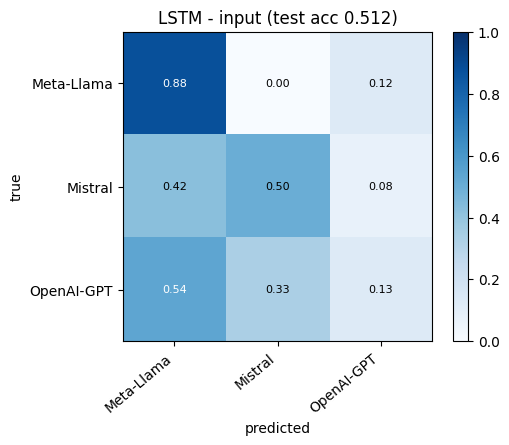

  LSTM/output epoch 1: loss 0.855  val acc 0.621
  LSTM/output epoch 2: loss 0.643  val acc 0.692
  LSTM/output epoch 3: loss 0.488  val acc 0.743
  LSTM/output epoch 4: loss 0.345  val acc 0.770
  LSTM/output epoch 5: loss 0.247  val acc 0.754
  LSTM/output epoch 6: loss 0.151  val acc 0.766
  LSTM/output epoch 7: loss 0.075  val acc 0.751
  LSTM/output epoch 8: loss 0.046  val acc 0.767
  LSTM/output epoch 9: loss 0.027  val acc 0.765
  LSTM/output epoch 10: loss 0.015  val acc 0.753
  LSTM/output epoch 11: loss 0.010  val acc 0.763
  LSTM/output epoch 12: loss 0.008  val acc 0.771


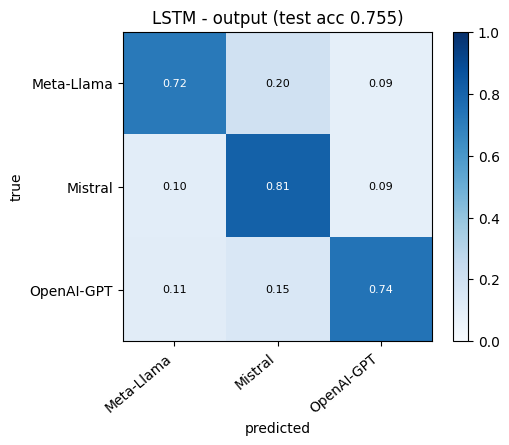

              precision    recall  f1-score   support

  Meta-Llama      0.782     0.717     0.748       240
     Mistral      0.701     0.810     0.752       232
  OpenAI-GPT      0.798     0.740     0.768       219

    accuracy                          0.755       691
   macro avg      0.760     0.756     0.756       691
weighted avg      0.760     0.755     0.756       691

  LSTM/both epoch 1: loss 0.943  val acc 0.483
  LSTM/both epoch 2: loss 0.870  val acc 0.536
  LSTM/both epoch 3: loss 0.799  val acc 0.565
  LSTM/both epoch 4: loss 0.684  val acc 0.585
  LSTM/both epoch 5: loss 0.551  val acc 0.601
  LSTM/both epoch 6: loss 0.428  val acc 0.595
  LSTM/both epoch 7: loss 0.348  val acc 0.580
  LSTM/both epoch 8: loss 0.231  val acc 0.607
  LSTM/both epoch 9: loss 0.145  val acc 0.574
  LSTM/both epoch 10: loss 0.096  val acc 0.598
  LSTM/both epoch 11: loss 0.098  val acc 0.588
  LSTM/both epoch 12: loss 0.067  val acc 0.588


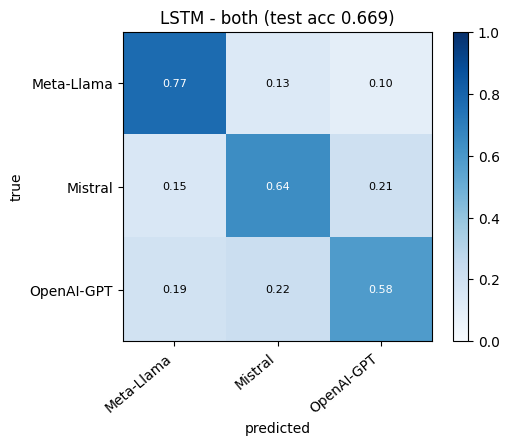

acc        macro_f1       
model       CNN   LSTM      CNN   LSTM
features                              
both      0.861  0.669    0.861  0.665
input     0.512  0.512    0.401  0.457
output    0.800  0.755    0.800  0.756

,family,CNN,LSTM
model,,,
llama-chat,Meta-Llama,0.808,0.717
mistral,Mistral,0.888,0.931
mistral-chat,Mistral,0.672,0.690
chatgpt,OpenAI-GPT,0.712,0.479
gpt3,OpenAI-GPT,0.767,1.000
gpt4,OpenAI-GPT,0.959,0.740


In [24]:
results, trained, histories, per_model = [], {}, {}, {}
for arch in MODELS:
    for mode in ["input", "output", "both"]:
        model, vocab, hist = fit(arch, train_df, val_df, mode)
        m, g, p = evaluate(model, vocab, test_df, mode)
        results.append({"model": arch, "features": mode, **m})
        trained[(arch, mode)] = (model, vocab); histories[f"{arch}/{mode}"] = hist
        plot_cm(g, p, f"{arch} - {mode} (test acc {m['acc']:.3f})", f"cm_{arch}_{mode}.png")
        if mode == "output":
            print(classification_report(g, p, target_names=CLASSES, digits=3))
            per_model[arch] = pd.Series(g == p).groupby(test_df["model"].values).mean()   # accuracy within each model

rq12 = pd.DataFrame(results); rq12.to_csv(f"{OUT_DIR}/rq1_rq2.csv", index=False)
display(rq12.pivot(index="features", columns="model", values=["acc", "macro_f1"]).round(3))

# Output-only accuracy broken down by the specific model inside each family
pm = pd.DataFrame(per_model).round(3); pm.index.name = "model"
pm.insert(0, "family", [FAMILY[m] for m in pm.index]); pm = pm.sort_values("family")
pm.to_csv(f"{OUT_DIR}/per_model_acc.csv"); display(pm)

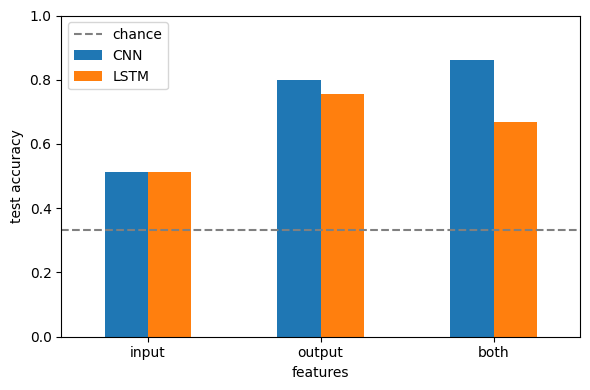

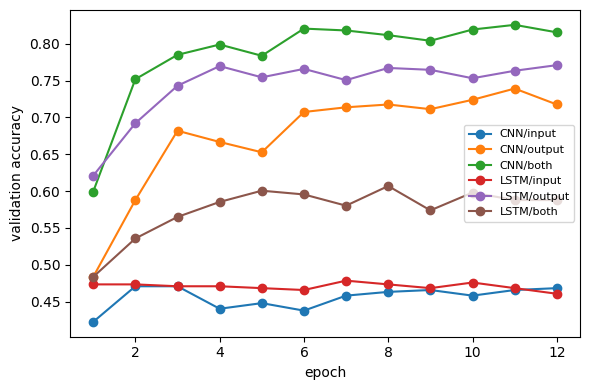

In [25]:
# Figures for the report: accuracy bars and validation curves
ax = rq12.pivot(index="features", columns="model", values="acc").loc[["input", "output", "both"]].plot.bar(rot=0, figsize=(6, 4))
ax.axhline(1 / len(CLASSES), ls="--", c="gray", label="chance"); ax.set_ylabel("test accuracy"); ax.set_ylim(0, 1); ax.legend()
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/rq1_rq2_bars.png", dpi=150); plt.show()

fig, ax = plt.subplots(figsize=(6, 4))
for k, h in histories.items(): ax.plot([e["epoch"] for e in h], [e["val_acc"] for e in h], marker="o", label=k)
ax.set_xlabel("epoch"); ax.set_ylabel("validation accuracy"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/val_curves.png", dpi=150); plt.show()

{'held_out': 'poetry', 'model': 'CNN', 'in_domain_acc': 0.7175572519083969, 'unseen_domain_acc': 0.4829024186822352, 'drop': 0.2346548332261617, 'unseen_macro_f1': 0.48501217022178555}


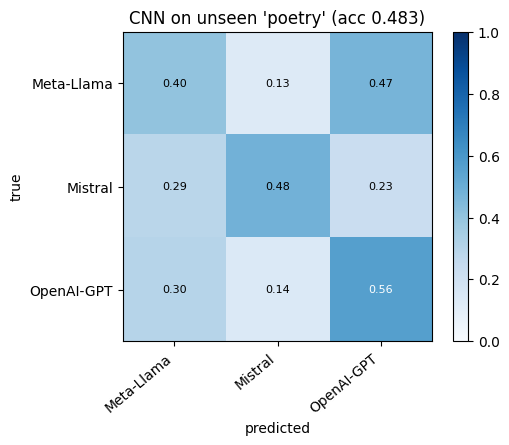

{'held_out': 'poetry', 'model': 'LSTM', 'in_domain_acc': 0.6564885496183206, 'unseen_domain_acc': 0.5170975813177648, 'drop': 0.13939096830055575, 'unseen_macro_f1': 0.4983858378173676}


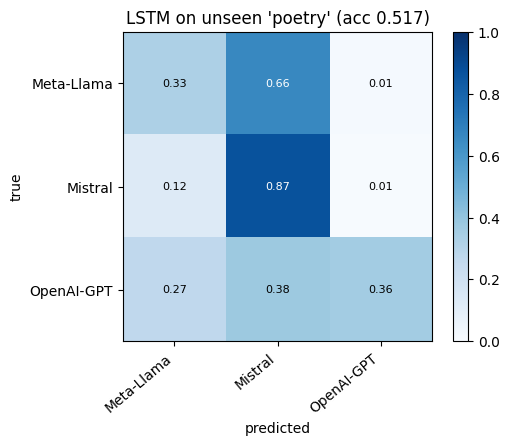

{'held_out': 'abstracts', 'model': 'CNN', 'in_domain_acc': 0.8918918918918919, 'unseen_domain_acc': 0.5054211843202668, 'drop': 0.38647070757162505, 'unseen_macro_f1': 0.4214695200015484}


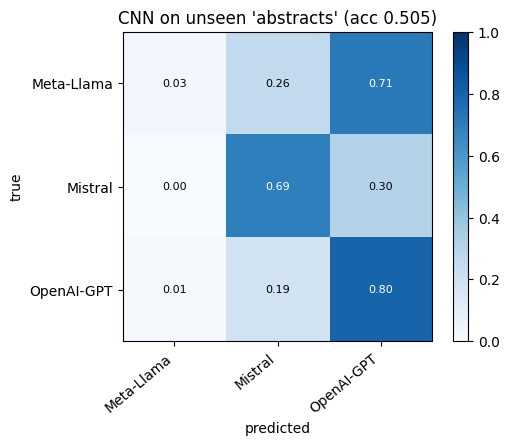

{'held_out': 'abstracts', 'model': 'LSTM', 'in_domain_acc': 0.8063063063063063, 'unseen_domain_acc': 0.4870725604670559, 'drop': 0.3192337458392504, 'unseen_macro_f1': 0.4101222929480121}


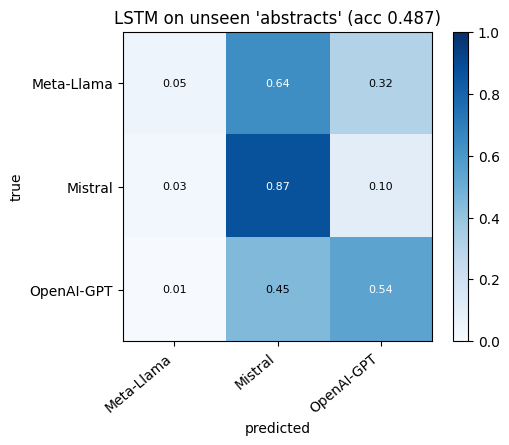

,held_out,model,in_domain_acc,unseen_domain_acc,drop,unseen_macro_f1
0,poetry,CNN,0.718,0.483,0.235,0.485
1,poetry,LSTM,0.656,0.517,0.139,0.498
2,abstracts,CNN,0.892,0.505,0.386,0.421
3,abstracts,LSTM,0.806,0.487,0.319,0.410


In [26]:
rq3 = []
for dom in HELD_OUT:
    rest, target = df[df.domain != dom], df[df.domain == dom].reset_index(drop=True)
    tr, va, _ = group_split(rest)                    # val also comes from the seen domains
    tr = pd.concat([tr, _]).reset_index(drop=True)   # no test needed from seen domains -> use it for training
    for arch in MODELS:
        model, vocab, _h = fit(arch, tr, va, "output", verbose=False)
        m, g, p = evaluate(model, vocab, target, "output")
        base_model, base_vocab = trained[(arch, "output")]
        b, _, _ = evaluate(base_model, base_vocab, test_df[test_df.domain == dom], "output")
        rq3.append({"held_out": dom, "model": arch, "in_domain_acc": b["acc"], "unseen_domain_acc": m["acc"],
                    "drop": b["acc"] - m["acc"], "unseen_macro_f1": m["macro_f1"]})
        print(rq3[-1])
        plot_cm(g, p, f"{arch} on unseen '{dom}' (acc {m['acc']:.3f})", f"rq3_cm_{arch}_{dom}.png")
rq3 = pd.DataFrame(rq3); rq3.to_csv(f"{OUT_DIR}/rq3.csv", index=False); display(rq3.round(3))

,n_tokens,type_token_ratio,words_per_sentence,avg_word_len,punct_per_100_tok,newlines
family,,,,,,
Meta-Llama,332.87,0.57,38.76,4.89,12.49,14.46
Mistral,277.44,0.58,38.14,4.78,11.93,14.69
OpenAI-GPT,253.95,0.59,23.98,4.88,12.95,12.96


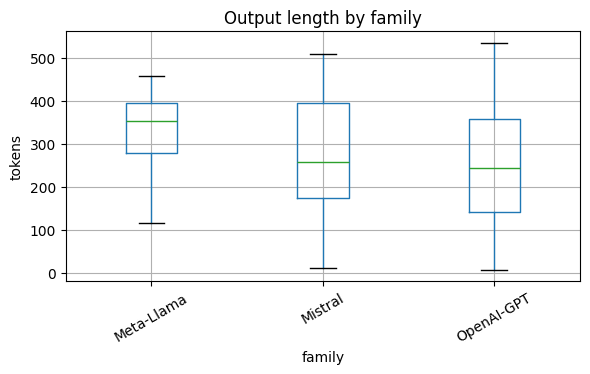

In [27]:
def stats(t):
    toks = tokenize(t); words = [w for w in toks if w[0].isalnum()]
    sents = max(1, len(re.findall(r"[.!?]+", t)))
    return {"n_tokens": len(toks), "type_token_ratio": len(set(w.lower() for w in words)) / max(1, len(words)),
            "words_per_sentence": len(words) / sents, "avg_word_len": np.mean([len(w) for w in words]) if words else 0,
            "punct_per_100_tok": 100 * sum(not w[0].isalnum() and w != "\n" for w in toks) / max(1, len(toks)),
            "newlines": t.count("\n")}

st = pd.concat([df[["family"]], pd.DataFrame([stats(t) for t in df["output"]])], axis=1)
fam_stats = st.groupby("family").mean().round(2); fam_stats.to_csv(f"{OUT_DIR}/rq4_stats.csv"); display(fam_stats)
st.boxplot(column="n_tokens", by="family", showfliers=False, rot=30, figsize=(6, 4))
plt.suptitle(""); plt.title("Output length by family"); plt.ylabel("tokens")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/rq4_length.png", dpi=150); plt.show()

In [28]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
tfidf = TfidfVectorizer(max_features=20000, ngram_range=(1, 2), min_df=3, sublinear_tf=True)
Xtr, Xte = tfidf.fit_transform(train_df["output"]), tfidf.transform(test_df["output"])
lr = LogisticRegression(max_iter=1000, C=5).fit(Xtr, train_df["y"])
print("TF-IDF + logistic regression baseline, test acc:", round(lr.score(Xte, test_df["y"]), 3))
names = np.array(tfidf.get_feature_names_out())
top = pd.DataFrame({CLASSES[c]: names[np.argsort(lr.coef_[c])[-15:][::-1]] for c in lr.classes_})
top.to_csv(f"{OUT_DIR}/rq4_top_words.csv", index=False); display(top)

TF-IDF + logistic regression baseline, test acc: 0.832


,Meta-Llama,Mistral,OpenAI-GPT
0,their,abstract,the
1,despite,very,this paper
2,that,how,the novel
3,has,at,segmentation
4,bright,some,paper presents
5,or,the paper,experimental results
6,including,another,silent
7,several,utilizes,paper
8,they,org,results on
9,that the,so,testament


,CNN,LSTM
ablation,,
original,0.800,0.755
first 32 tokens,0.524,0.712
lowercased,0.766,0.712
no punctuation,0.650,0.660
no line breaks,0.693,0.669
word order shuffled,0.511,0.436


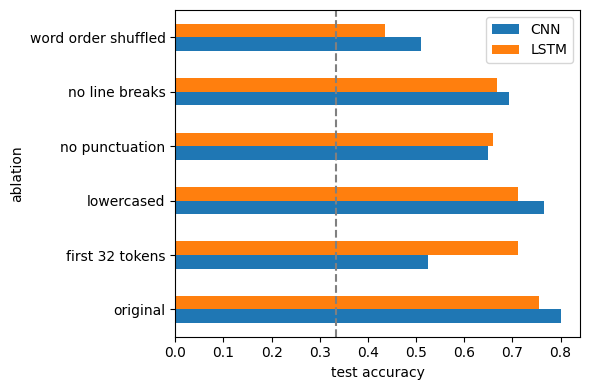

In [29]:
def ablate(d, fn):
    d = d.copy(); d["output"] = d["output"].map(fn); return d

rng = random.Random(SEED)
def shuffle_words(t):
    w = t.split(); rng.shuffle(w); return " ".join(w)

ABLATIONS = {
    "original":            lambda t: t,
    "first 32 tokens":     lambda t: " ".join(tokenize(t)[:32]),
    "lowercased":          lambda t: t.lower(),
    "no punctuation":      lambda t: re.sub(r"[^\w\s]", "", t),
    "no line breaks":      lambda t: re.sub(r"\s+", " ", t),
    "word order shuffled": shuffle_words,
}
abl = []
for name, fn in ABLATIONS.items():
    d = ablate(test_df, fn)
    row = {"ablation": name}
    for arch in MODELS:
        model, vocab = trained[(arch, "output")]
        row[arch] = evaluate(model, vocab, d, "output")[0]["acc"]
    abl.append(row)
abl = pd.DataFrame(abl).set_index("ablation"); abl.to_csv(f"{OUT_DIR}/rq4_ablations.csv"); display(abl.round(3))
abl.plot.barh(figsize=(6, 4)); plt.axvline(1 / len(CLASSES), ls="--", c="gray"); plt.xlabel("test accuracy")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/rq4_ablations.png", dpi=150); plt.show()

In [30]:
json.dump(histories, open(f"{OUT_DIR}/histories.json", "w"))
!zip -qr results.zip results
try:
    from google.colab import files; files.download("results.zip")
except Exception as e:
    print("not in Colab; results are in", OUT_DIR)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>